## Análise Comparativa do Modelo Base no CFIMDB

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.metrics import accuracy_score, confusion_matrix
from IPython.display import display, HTML
from deep_translator import GoogleTranslator

plt.style.use('ggplot')
sns.set_palette("pastel")

In [2]:
# Função para estilização de DataFrames
def styled_sentiment_examples(df):
    return df.style.set_properties(**{
        'background-color': '#f8f9fa',
        'border': '1px solid #dee2e6',
        'padding': '5px',
        'color': '#212529'
    }).set_table_styles([{
        'selector': 'th',
        'props': [('background-color', '#343a40'), ('color', 'white')]
    }])

In [10]:
# Traduzir sentenças para português
def translate_sentence(sentence):
    try:
        return GoogleTranslator(source='en', target='pt').translate(sentence)
    except Exception as e:
        print(f"Erro ao traduzir: {e}")
        return sentence  # Retorna original se houver erro

## Análise do CFIMDB

In [3]:
# Carregar dados CFIMDB
cfimdb_dev = pd.read_csv('../data/ids-cfimdb-dev.csv', sep='\t')[['id', 'sentence', 'sentiment']]

# Carregar previsões
cfimdb_pretrain = pd.read_csv('../predictions/sst_v1_base_model/pretrain-cfimdb-dev-out.csv')
cfimdb_finetune = pd.read_csv('../predictions/sst_v1_base_model/finetune-cfimdb-dev-out.csv')

# Combinar dados
cfimdb_analysis = cfimdb_pretrain.merge(
    cfimdb_finetune, on='id', suffixes=('_pretrain', '_finetune')
).merge(cfimdb_dev, on='id')

### Métricas CFIMDB

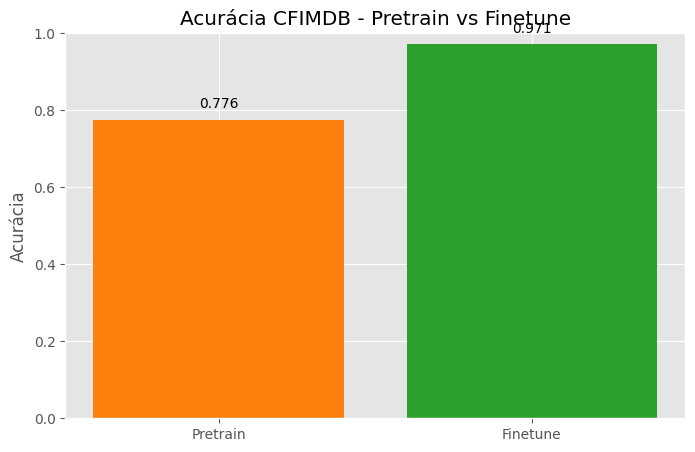

In [4]:
# Calcular acurácias
acc_pretrain = accuracy_score(cfimdb_analysis['sentiment'], cfimdb_analysis['Predicted_Sentiment_pretrain'])
acc_finetune = accuracy_score(cfimdb_analysis['sentiment'], cfimdb_analysis['Predicted_Sentiment_finetune'])

plt.figure(figsize=(8,5))
plt.bar(['Pretrain', 'Finetune'], [acc_pretrain, acc_finetune], color=['#ff7f0e', '#2ca02c'])
plt.title('Acurácia CFIMDB - Pretrain vs Finetune')
plt.ylim(0, 1)
plt.ylabel('Acurácia')
for i, v in enumerate([acc_pretrain, acc_finetune]):
    plt.text(i, v + 0.03, f"{v:.3f}", ha='center')
plt.show()

### Exemplos de Melhoria CFIMDB

In [9]:
# Filtrar casos onde finetune corrigiu pretrain
cfimdb_improvements = cfimdb_analysis[
    (cfimdb_analysis['Predicted_Sentiment_finetune'] == cfimdb_analysis['sentiment']) &
    (cfimdb_analysis['Predicted_Sentiment_pretrain'] != cfimdb_analysis['sentiment'])
]

# printa quantidade de melhorias
print(f"Quantidade de melhorias: {cfimdb_improvements.shape[0]}")

# pegar apenas textos curtos para melhor visualização
cfimdb_improvements = cfimdb_improvements[cfimdb_improvements['sentence'].str.len() < 800] 
cfimdb_improvements = cfimdb_improvements.sample(3)

Quantidade de melhorias: 53


In [14]:
# Mapear sentimentos
sentiment_map = {0: 'Negative', 1: 'Positive'}
examples = cfimdb_improvements.loc[:, ['sentence', 'sentiment', 'Predicted_Sentiment_pretrain', 'Predicted_Sentiment_finetune']]
examples['sentence'] = examples['sentence'].apply(translate_sentence)
examples['sentiment'] = examples['sentiment'].map(sentiment_map)
examples['Predicted_Sentiment_pretrain'] = examples['Predicted_Sentiment_pretrain'].map(sentiment_map)
examples['Predicted_Sentiment_finetune'] = examples['Predicted_Sentiment_finetune'].map(sentiment_map)

display(styled_sentiment_examples(examples.rename(columns={
    'sentiment': 'Real',
    'Predicted_Sentiment_pretrain': 'Pretrain',
    'Predicted_Sentiment_finetune': 'Finetune'
})))

,sentence,Real,Pretrain,Finetune
94,"Crescendo em um bairro multirracial nos anos 20 e 30, cresci muito perto da maioria das famílias italianas que moravam lá. Este filme não traz nenhuma lembrança agradável. Este é um filme que a maioria das pessoas odiaria, que gostam de ver filmes mais realistas.",Negative,Positive,Negative
178,"Achei esse filme um estudo pobre de uma família em crise. Quando Leo, o mais velho, anuncia que é HIV+, as reações dos membros da família, sozinhos e uns com os outros, foram frias e estranhas.Nunca vi uma família tão fisicamente demonstrativa quanto essa; nem uma tão propensa a gritar uns com os outros. Não entendi por que a família sentiu que o mais novo não conseguia lidar com a notícia, mas depois de passar por essa dificuldade, achei esse um filme completamente perturbador.",Negative,Positive,Negative
124,"Um filme chato. A atuação chata de sempre de John Thaw, que faleceu recentemente. Um homem que sempre foi tão presunçoso. Ele foi um dos 10 piores atores da Inglaterra, certamente do meu tempo.Ele pode ser lembrado por seu famoso papel de Inspetor Morse. Como Jack Regan na série de TV de sucesso dos anos 1970 'the Sweeney' e como um advogado em Kavanah QC. Um nunca visto para toda a família e um ótimo DVD nunca para minha coleção. A filmagem trará de volta algumas memórias para as pessoas que se lembram da Grã-Bretanha em tempo de guerra e certamente aqueles que foram evacuados de Londres para escapar dos bombardeios alemães. A interação entre os dois personagens principais. Tom e o menino William foi realmente mal interpretado e não fiel ao livro de Michelle Magorian.",Negative,Positive,Negative


### Nuvem de Palavras CFIMDB

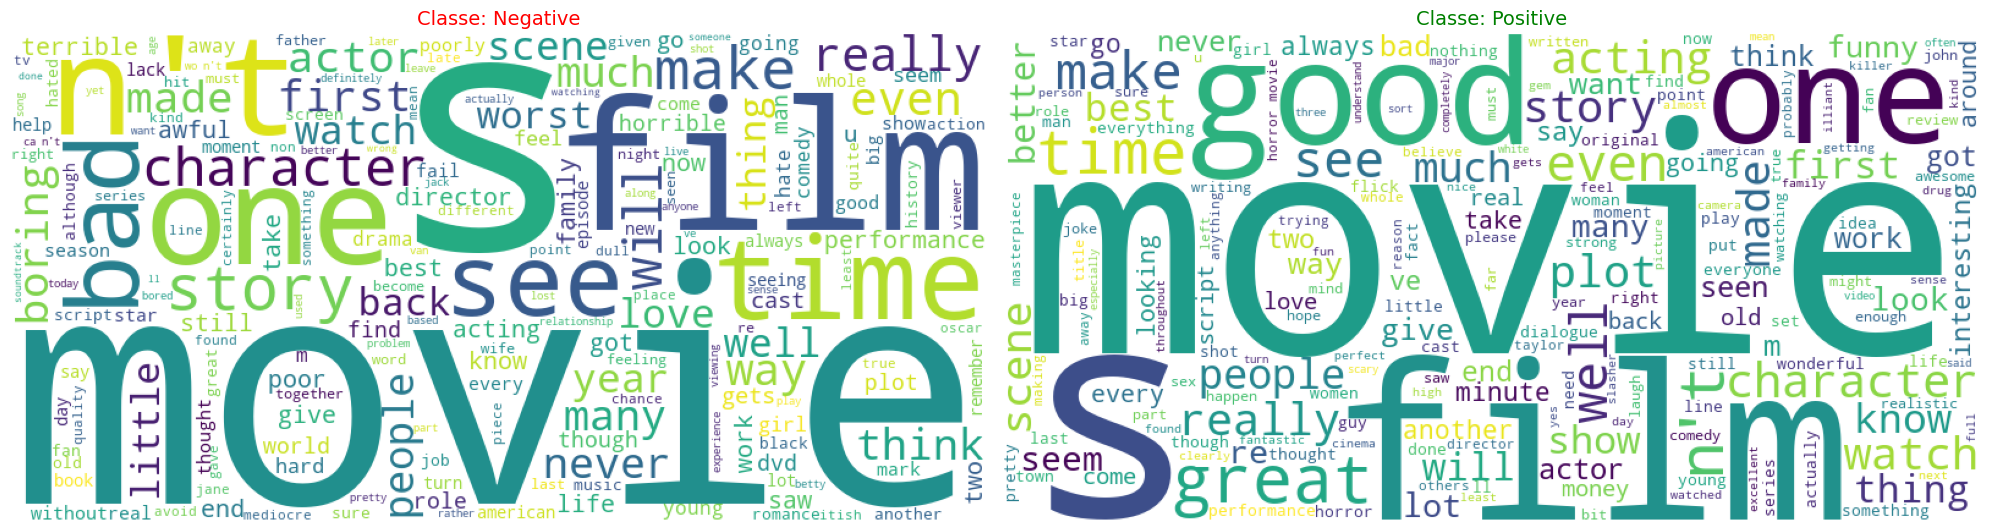

In [8]:
def generate_wordclouds(df, sentiment_col):
    fig, axs = plt.subplots(1, 2, figsize=(20, 8))
    
    color_map = {0: 'red', 1: 'green'} 

    for i, sentiment in enumerate([0, 1]):
        text = ' '.join(df[df[sentiment_col] == sentiment]['sentence'].dropna().astype(str).str.lower())
        text = text.replace("br", "")
        wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
        
        axs[i].imshow(wordcloud)
        axs[i].set_title(f'Classe: {sentiment_map[sentiment]}', fontsize=14, color=color_map[sentiment])
        axs[i].axis('off')
    
    plt.tight_layout()
    plt.show()

# Chamada da função com o dataframe filtrado
generate_wordclouds(
    cfimdb_analysis[cfimdb_analysis['Predicted_Sentiment_finetune'] == cfimdb_analysis['sentiment']], 
    'sentiment'
)
